## 04 Modeling

Phần đầu kiểm tra overfitting và data leakage với mô hình dự đoán Peak CCU. Phần bổ sung ở cuối notebook là hồi quy và phân loại trên dữ liệu từ notebook 03.

### Nhiệm vụ #44 – Kiểm tra Overfitting và Data Leakage
 

#### Xác định dữ liệu và mục tiêu dự đoán

In [2]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "games_cleaned.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

# Bỏ nhóm owners = "0 - 0" vì đây là thiếu dữ liệu, nếu giữ thì nhãn Peak CCU = 0 sẽ sai (notebook 01, mục A3)
df = df[df["Estimated owners"] != "0 - 0"].reset_index(drop=True)

print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách các cột:")
print(df.columns.tolist())

print("\nNăm dòng dữ liệu đầu tiên:")
display(df.head())


Kích thước dữ liệu: (101274, 21)

Danh sách các cột:
['id', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Price', 'Discount', 'DLC count', 'Positive', 'Negative', 'User score', 'Metacritic score', 'Recommendations', 'Achievements', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Categories', 'Genres', 'Tags']

Năm dòng dữ liệu đầu tiên:


,id,Name,Release date,Estimated owners,Peak CCU,Price,Discount,DLC count,Positive,Negative,...,Metacritic score,Recommendations,Achievements,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Categories,Genres,Tags
0,10,Counter-Strike,2000-11-01,10000000 - 20000000,7323,1.99,80,0,243818,6427,...,88.0,164682,0,10735,836,185,99,"Multi-player,PvP,Online PvP,Shared/Split Scree...",Action,"Action,FPS,Multiplayer,Shooter,Classic,Team-Ba..."
1,20,Team Fortress Classic,1999-04-01,1000000 - 2000000,66,1.24,75,0,7602,1136,...,NaN,6742,0,466,0,13,0,"Multi-player,PvP,Online PvP,Shared/Split Scree...",Action,"Action,FPS,Multiplayer,Classic,Hero Shooter,Sh..."
2,30,Day of Defeat,2003-05-01,5000000 - 10000000,87,1.24,75,0,6414,688,...,79.0,4351,0,997,948,17,948,"Multi-player,Camera Comfort,Color Alternatives...",Action,"FPS,World War II,Multiplayer,Shooter,Action,Wa..."
3,40,Deathmatch Classic,2001-06-01,5000000 - 10000000,7,1.24,75,0,2618,545,...,NaN,2360,0,339,0,7,0,"Multi-player,PvP,Online PvP,Shared/Split Scree...",Action,"Action,FPS,Classic,Multiplayer,Shooter,First-P..."
4,50,Half-Life: Opposing Force,1999-11-01,2000000 - 5000000,74,1.24,75,0,24363,1198,...,NaN,23464,0,415,2,202,2,"Single-player,Multi-player,Custom Volume Contr...",Action,"FPS,Action,Classic,Sci-fi,Singleplayer,Shooter..."


#### Chọn mục tiêu dự đoán
Mục tiêu dự đoán	Ý nghĩa	Lưu ý
Peak CCU	Lượng người chơi đồng thời cao nhất	Phù hợp để thử dự đoán mức độ thu hút người chơi
Positive	Số lượt đánh giá tích cực	Có thể chịu ảnh hưởng lớn từ quy mô người chơi
Price	Giá game	Có thể thử dự đoán giá dựa trên các thuộc tính của game
→ Chọn Peak CCU trước.

#### Kiểm tra dữ liệu trước khi xây dựng mô hình

In [2]:
# Kiểm tra các cột có thể dùng để dự đoán Peak CCU

target = "Peak CCU"

candidate_features = [
    "Price",
    "Discount",
    "DLC count",
    "Achievements",
    "Metacritic score",
    "User score",
    "Positive",
    "Negative",
    "Recommendations",
    "Average playtime forever",
    "Average playtime two weeks",
    "Median playtime forever",
    "Median playtime two weeks",
]

print("Mục tiêu dự đoán:", target)

print("\nKiểu dữ liệu của các cột:")
display(df[[target] + candidate_features].dtypes.to_frame("Data type"))

print("\nSố lượng giá trị thiếu:")
display(df[[target] + candidate_features].isna().sum().to_frame("Missing values"))

print("\nThống kê mô tả:")
display(df[[target] + candidate_features].describe().T)

Mục tiêu dự đoán: Peak CCU

Kiểu dữ liệu của các cột:


,Data type
Peak CCU,int64
Price,float64
Discount,int64
DLC count,int64
Achievements,int64
Metacritic score,float64
User score,float64
Positive,int64
Negative,int64
Recommendations,int64



Số lượng giá trị thiếu:


,Missing values
Peak CCU,0
Price,0
Discount,0
DLC count,0
Achievements,0
Metacritic score,97038
User score,101234
Positive,0
Negative,0
Recommendations,0



Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
Peak CCU,101274.0,66.096678,4103.470128,0.0,0.00,0.00,0.00,1013936.00
Price,101274.0,5.305699,11.793481,0.0,0.99,2.99,5.99,999.98
Discount,101274.0,22.221478,30.357264,0.0,0.00,0.00,50.00,100.00
DLC count,101274.0,0.620396,15.945637,0.0,0.00,0.00,0.00,3703.00
Achievements,101274.0,20.544128,155.239206,0.0,0.00,6.00,21.00,9821.00
Metacritic score,4236.0,73.919736,10.258348,6.0,68.00,76.00,81.00,97.00
User score,40.0,75.250000,17.642824,37.0,62.50,77.00,89.00,100.00
Positive,101274.0,1265.312983,30905.187922,0.0,1.00,10.00,59.00,7642084.00
Negative,101274.0,204.897605,5913.181358,0.0,0.00,2.00,16.00,1173003.00
Recommendations,101274.0,1161.771432,24066.533581,0.0,0.00,0.00,0.00,4830455.00


#### Tạo mô hình thử nghiệm để kiểm tra overfitting
Chia dữ liệu thành tập huấn luyện và tập kiểm tra.



Dùng log1p(Peak CCU) để giảm ảnh hưởng của các giá trị CCU cực lớn.



So sánh mô hình đơn giản với Random Forest.



So sánh sai số giữa train và test để phát hiện dấu hiệu overfitting.

In [3]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Chọn các đặc trưng cơ bản, tránh dùng số liệu đánh giá
# (giá, giảm giá, số DLC, số thành tựu: các đặc điểm của game liên quan RQ1 và RQ5)
features = [
    "Price",
    "Discount",
    "DLC count",
    "Achievements"
]

target = "Peak CCU"

# Chuyển các cột đầu vào về dạng số nếu có thể
X = df[features].copy()

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

y = np.log1p(df[target])

# Chia train/test trước khi huấn luyện
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Baseline": make_pipeline(
        SimpleImputer(strategy="median"),
        DummyRegressor(strategy="median")
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Train MAE,Test MAE,Train R2,Test R2
0,Baseline,0.4019,0.4103,-0.1272,-0.1275
1,Random Forest,0.4420,0.4783,0.4377,0.3223


Cách đọc kết quả
- Train MAE thấp nhưng Test MAE cao hơn nhiều: mô hình có dấu hiệu overfitting.
- Train và Test MAE đều cao: mô hình có thể chưa học được quy luật hữu ích.
- Random Forest tốt hơn Baseline trên tập test: có dấu hiệu mô hình học được thông tin hữu ích từ các đặc trưng đã chọn.
- Test R² âm: mô hình dự đoán còn kém hơn một phương án đơn giản dự đoán bằng giá trị trung bình của tập test.

#### Kiểm tra lại đặc điểm dữ liệu
Kết quả này giúp xác định vì sao mô hình khó dự đoán: dữ liệu có thể tập trung quá nhiều ở mức CCU bằng 0, trong khi một số ít game có giá trị cực lớn.

In [4]:
print("Tỷ lệ Peak CCU bằng 0:")
print((df["Peak CCU"] == 0).mean() * 100, "%")

print("\nSố game có Peak CCU > 0:")
print((df["Peak CCU"] > 0).sum())

print("\nCác phân vị của Peak CCU:")
display(df["Peak CCU"].quantile([0, 0.5, 0.75, 0.9, 0.95, 0.99, 1]))

Tỷ lệ Peak CCU bằng 0:
80.56756916878962 %

Số game có Peak CCU > 0:
19680

Các phân vị của Peak CCU:


0.00          0.0
0.50          0.0
0.75          0.0
0.90          3.0
0.95         14.0
0.99        311.0
1.00    1013936.0
Name: Peak CCU, dtype: float64


Kết quả này xác nhận một vấn đề quan trọng: dữ liệu Peak CCU bị lệch rất mạnh về phía 0. Đây có thể là một trong những nguyên nhân khiến mô hình khó dự đoán chính xác lượng người chơi.

In [5]:
#Ý nghĩa nhãn: 0 là game có Peak CCU = 0; 1 là game có Peak CCU > 0.

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Chọn đặc trưng và tạo nhãn phân loại
features = ["Price", "Discount", "DLC count", "Achievements"]

X = df[features].copy()
y = (df["Peak CCU"] > 0).astype(int)

# Chuyển dữ liệu đầu vào về dạng số
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Chia tập train và test, giữ tỷ lệ hai nhóm
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Xây dựng mô hình phân loại
model_stage1 = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

model_stage1.fit(X_train, y_train)

# Dự đoán trên train và test
train_pred = model_stage1.predict(X_train)
test_pred = model_stage1.predict(X_test)

# Đánh giá kết quả
print("Accuracy train:", round(accuracy_score(y_train, train_pred), 4))
print("Accuracy test:", round(accuracy_score(y_test, test_pred), 4))

print("\nF1-score test:", round(f1_score(y_test, test_pred), 4))

print("\nClassification report trên tập test:")
print(classification_report(
    y_test, test_pred,
    target_names=["Peak CCU = 0", "Peak CCU > 0"],
    zero_division=0
))

print("Confusion matrix trên tập test:")
display(pd.DataFrame(
    confusion_matrix(y_test, test_pred),
    index=["Thực tế = 0", "Thực tế > 0"],
    columns=["Dự đoán = 0", "Dự đoán > 0"]
))

Accuracy train: 0.7631
Accuracy test: 0.7438

F1-score test: 0.4965

Classification report trên tập test:
              precision    recall  f1-score   support

Peak CCU = 0       0.90      0.77      0.83     16319
Peak CCU > 0       0.40      0.65      0.50      3936

    accuracy                           0.74     20255
   macro avg       0.65      0.71      0.66     20255
weighted avg       0.80      0.74      0.76     20255

Confusion matrix trên tập test:


,Dự đoán = 0,Dự đoán > 0
Thực tế = 0,12508,3811
Thực tế > 0,1378,2558


Kết quả giai đoạn 1 cho thấy mô hình phát hiện được một phần game có Peak CCU > 0, nhưng vẫn dự đoán nhầm khá nhiều.

#### Giai đoạn 2: dự đoán lượng Peak CCU của các game có CCU lớn hơn 0
Lưu ý: Giai đoạn 2 chỉ đánh giá hồi quy trên các game thực sự có Peak CCU > 0. Kết quả này chưa đại diện cho hiệu quả toàn bộ mô hình hai giai đoạn, vì chưa tính các lỗi phân loại từ giai đoạn 1.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import numpy as np
import pandas as pd

# Chọn các game có Peak CCU > 0
positive_mask = df["Peak CCU"] > 0

X_positive = df.loc[positive_mask, features].copy()
y_positive = np.log1p(df.loc[positive_mask, "Peak CCU"])

# Chuyển các đặc trưng về dạng số
for col in X_positive.columns:
    X_positive[col] = pd.to_numeric(X_positive[col], errors="coerce")

# Chia dữ liệu theo đúng các chỉ số train/test đã dùng ở giai đoạn 1
train_index = X_train.index.intersection(X_positive.index)
test_index = X_test.index.intersection(X_positive.index)

X_train_stage2 = X_positive.loc[train_index]
y_train_stage2 = y_positive.loc[train_index]

X_test_stage2 = X_positive.loc[test_index]
y_test_stage2 = y_positive.loc[test_index]

# Tạo và huấn luyện mô hình hồi quy
model_stage2 = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
)

model_stage2.fit(X_train_stage2, y_train_stage2)

# Dự đoán trên train và test
train_pred_stage2 = model_stage2.predict(X_train_stage2)
test_pred_stage2 = model_stage2.predict(X_test_stage2)

# Đánh giá trên thang log
print("Số game CCU > 0 trong train:", len(X_train_stage2))
print("Số game CCU > 0 trong test:", len(X_test_stage2))

print("\nTrain MAE:", round(
    mean_absolute_error(y_train_stage2, train_pred_stage2), 4
))
print("Test MAE:", round(
    mean_absolute_error(y_test_stage2, test_pred_stage2), 4
))
print("Train R2:", round(
    r2_score(y_train_stage2, train_pred_stage2), 4
))
print("Test R2:", round(
    r2_score(y_test_stage2, test_pred_stage2), 4
))

Số game CCU > 0 trong train: 15744
Số game CCU > 0 trong test: 3936

Train MAE: 0.9899
Test MAE: 1.102
Train R2: 0.4335
Test R2: 0.2588


Đánh giá kết quả
Chỉ số	Train	Test
MAE (thang log)	0.9899	1.1020
R²	0.4335	0.2588

- Overfitting: MAE giữa train và test chênh 0.1121, R² chênh 0.1747. R² trên tập test thấp hơn khá nhiều so với tập train, nên có dấu hiệu overfitting nhẹ.
- Khả năng dự đoán: Test R² = 0.2588, nghĩa là mô hình giải thích được khoảng 25,88% biến thiên của mục tiêu trên thang log.
- Sai số: MAE được tính trên log1p(Peak CCU), không phải số người chơi trực tiếp.

#### Kết hợp hai giai đoạn
Cách tính:
- Nếu giai đoạn 1 dự đoán CCU = 0, dự đoán cuối cùng là 0.
- Nếu giai đoạn 1 dự đoán CCU > 0, lấy dự đoán hồi quy của giai đoạn 2 rồi chuyển về thang CCU bằng expm1.
- So sánh dự đoán cuối cùng với Peak CCU thực tế trên toàn bộ tập test.
**Lưu ý:** Đoạn code này giả định hai mô hình đã được huấn luyện bằng đúng các đặc trưng và cách chia dữ liệu hiện tại. Chỉ số MAE và R² cuối cùng được tính trên thang CCU gốc; do đó không so sánh trực tiếp MAE này với MAE trên thang log ở giai đoạn 2.

In [7]:
# Kết hợp dự đoán của hai giai đoạn trên tập test

stage1_pred = model_stage1.predict(X_test)

stage2_pred_log = model_stage2.predict(X_test)
stage2_pred_ccu = np.expm1(stage2_pred_log)

# Chỉ giữ dự đoán CCU dương nếu giai đoạn 1 phân loại là dương
final_pred = np.where(stage1_pred == 1, stage2_pred_ccu, 0)

# Giá trị CCU thực tế trên toàn bộ tập test
y_test_ccu = df.loc[X_test.index, "Peak CCU"].to_numpy()

print("MAE toàn bộ test:", round(
    mean_absolute_error(y_test_ccu, final_pred), 2
))
print("R2 toàn bộ test:", round(
    r2_score(y_test_ccu, final_pred), 4
))

MAE toàn bộ test: 38.09
R2 toàn bộ test: 0.0049


Kết luận nhiệm vụ # 44 đến hiện tại
- Overfitting: Giai đoạn 1 có chênh lệch nhỏ (accuracy train 0,763, test 0,744). Giai đoạn 2 có dấu hiệu overfitting nhẹ (R² train 0,434, test 0,259).
- Data leakage: Đã hạn chế một số nguy cơ bằng cách không dùng các cột đánh giá và đề xuất, nhưng chưa thể khẳng định đã loại bỏ hoàn toàn leakage.
- Hiệu quả mô hình: Mô hình hai giai đoạn có R² toàn bộ test chỉ 0,0049, nên khả năng dự đoán CCU thực tế còn yếu.
- Nguyên nhân cần xem xét: 80,57% game có CCU bằng 0, phân bố lệch mạnh và các đặc trưng hiện tại (Price, Discount, DLC count, Achievements) có thể chưa đủ thông tin để dự đoán mức độ phổ biến.

### Phần bổ sung: hồi quy và phân loại trên dữ liệu đã chuẩn bị ở notebook 03

Phần trên dùng 4 đặc trưng. Phần này khác ở ba điểm:

- Dùng `games_features.csv` từ notebook 03, đã bỏ thêm năm 2026 và các game thiếu Genres, Categories.
- Dùng thêm thể loại, tính năng và năm phát hành. Không dùng Discount và DLC count vì đây là trạng thái sau khi phát hành.
- Dùng cách chia train/test có sẵn trong cột `split`, để notebook 05 và 07 đánh giá đúng trên tập test này.

Phần này gồm hồi quy tuyến tính để xem từng yếu tố liên hệ với kết quả như thế nào khi giữ các yếu tố khác không đổi, và mô hình phân loại để dự đoán game có người chơi đồng thời hay không.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import statsmodels.api as sm

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import f1_score, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="Set2")

data = pd.read_csv("../data/processed/games_features.csv", low_memory=False)
print("Kích thước dữ liệu:", data.shape)

cot_the_loai = [c for c in data.columns if c.startswith("genre_")]
cot_tinh_nang = [c for c in data.columns if c.startswith("cat_")]

# Đặc trưng cho hồi quy tuyến tính
dac_trung_hoi_quy = ["log_price", "is_free", "has_achievements", "Năm phát hành"] + cot_the_loai + cot_tinh_nang

# Đặc trưng cho mô hình phân loại
dac_trung_phan_loai = ["log_price", "is_free", "has_achievements", "log_achievements",
                       "Năm phát hành", "n_genres"] + cot_the_loai + cot_tinh_nang

Kích thước dữ liệu: (100025, 43)


Ghi chú về phần trên: ở bảng đầu tiên, baseline có Test MAE thấp hơn Random Forest (0,4103 so với 0,4783) dù R2 kém hơn. Lý do là phần lớn game có Peak CCU = 0 nên đoán luôn bằng 0 đã có sai số tuyệt đối nhỏ. Vì vậy chỉ nhìn MAE thì chưa đủ.

#### Hồi quy tuyến tính cho từng câu hỏi nghiên cứu

Mỗi mô hình có một biến mục tiêu:

| Mô hình | Biến mục tiêu | Dữ liệu dùng | Câu hỏi liên quan |
|---|---|---|---|
| A | log1p(Total reviews) | Tất cả game | RQ1, RQ4, RQ5 |
| B | Positive ratio (%) | Game có từ 10 đánh giá | RQ2, RQ4, RQ5 |
| C | log1p(Median playtime forever) | Game có thời gian chơi > 0 | RQ3 |

Dùng Total reviews thay cho Peak CCU ở mô hình A vì Peak CCU có quá nhiều số 0, hồi quy tuyến tính không phù hợp. Sai số chuẩn dùng HC3 vì phương sai sai số không đều giữa các game.

In [9]:
# Tạo 3 bộ dữ liệu cho 3 mô hình
bo_du_lieu = {
    "A: Số đánh giá": (data, "log_reviews"),
    "B: Tỷ lệ tích cực": (data[data["Positive ratio"].notna()], "Positive ratio"),
    "C: Thời gian chơi": (data[data["Median playtime forever"] > 0], "log_playtime"),
}

ket_qua_ols = {}
for ten, (du_lieu, muc_tieu) in bo_du_lieu.items():
    train = du_lieu[du_lieu["split"] == "train"]
    test = du_lieu[du_lieu["split"] == "test"]

    X_train = sm.add_constant(train[dac_trung_hoi_quy])
    X_test = sm.add_constant(test[dac_trung_hoi_quy])

    mo_hinh = sm.OLS(train[muc_tieu], X_train).fit(cov_type="HC3")
    ket_qua_ols[ten] = mo_hinh

    print(ten)
    print("  Số game train:", len(train), "- test:", len(test))
    print("  R2 train:", round(mo_hinh.rsquared, 3))
    print("  R2 test:", round(r2_score(test[muc_tieu], mo_hinh.predict(X_test)), 3))

A: Số đánh giá
  Số game train: 80020 - test: 20005
  R2 train: 0.357
  R2 test: 0.365
B: Tỷ lệ tích cực
  Số game train: 44824 - test: 11342


  R2 train: 0.132
  R2 test: 0.134
C: Thời gian chơi
  Số game train: 20624 - test: 5288
  R2 train: 0.122
  R2 test: 0.138


In [10]:
# Bảng hệ số của 3 mô hình, kèm dấu * nếu p < 0.05
bang_he_so = pd.DataFrame(index=dac_trung_hoi_quy)
for ten, mo_hinh in ket_qua_ols.items():
    cot = []
    for bien in dac_trung_hoi_quy:
        gia_tri = str(round(mo_hinh.params[bien], 3))
        if mo_hinh.pvalues[bien] < 0.05:
            gia_tri = gia_tri + " *"
        cot.append(gia_tri)
    bang_he_so[ten] = cot

display(bang_he_so)

,A: Số đánh giá,B: Tỷ lệ tích cực,C: Thời gian chơi
log_price,0.2 *,1.418 *,0.345 *
is_free,0.85 *,3.469 *,0.117 *
has_achievements,0.787 *,3.468 *,0.349 *
Năm phát hành,-0.335 *,1.012 *,-0.006 *
genre_Indie,-0.166 *,0.32,-0.218 *
genre_Casual,-0.445 *,1.203 *,-0.109 *
genre_Action,-0.06 *,-2.898 *,-0.2 *
genre_Adventure,0.311 *,-1.563 *,0.079 *
genre_Simulation,0.476 *,-5.139 *,0.105 *
genre_Strategy,0.128 *,-2.127 *,0.209 *


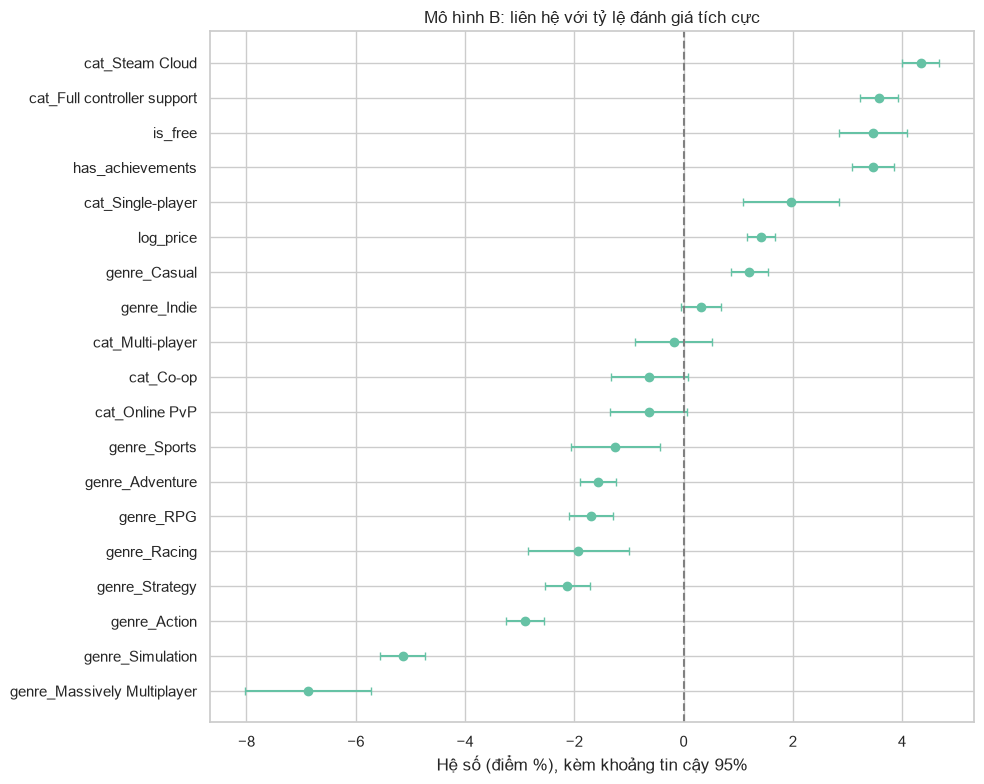

In [11]:
# Biểu đồ hệ số và khoảng tin cậy 95% của mô hình B
mo_hinh_b = ket_qua_ols["B: Tỷ lệ tích cực"]
khoang = mo_hinh_b.conf_int()
bien_ve = [b for b in dac_trung_hoi_quy if b not in ["Năm phát hành"]]
bang_ve = pd.DataFrame({
    "he_so": mo_hinh_b.params[bien_ve],
    "thap": khoang.loc[bien_ve, 0],
    "cao": khoang.loc[bien_ve, 1],
}).sort_values("he_so")

plt.figure(figsize=(10, 8))
plt.errorbar(bang_ve["he_so"], bang_ve.index,
             xerr=[bang_ve["he_so"] - bang_ve["thap"], bang_ve["cao"] - bang_ve["he_so"]],
             fmt="o", capsize=3)
plt.axvline(0, color="gray", linestyle="--")
plt.title("Mô hình B: liên hệ với tỷ lệ đánh giá tích cực")
plt.xlabel("Hệ số (điểm %), kèm khoảng tin cậy 95%")
plt.tight_layout()
plt.show()

Cách đọc bảng hệ số:

- Mô hình B có mục tiêu là điểm %, nên hệ số 3,468 của has_achievements nghĩa là game có Achievements có tỷ lệ tích cực cao hơn khoảng 3,5 điểm, khi các yếu tố khác giữ nguyên.
- Mô hình A và C có mục tiêu ở thang log, nên lấy e mũ hệ số. Ví dụ hệ số 0,787 nghĩa là số đánh giá gấp khoảng 2,2 lần.
- Dấu * nghĩa là p < 0,05.

Nhận xét:

- RQ1: Steam Cloud (gấp khoảng 2,3 lần) và Achievements (gấp khoảng 2,2 lần) đi kèm nhiều đánh giá hơn. Trong các thể loại, Simulation và Massively Multiplayer cao nhất, Casual thấp nhất.
- RQ2: Massively Multiplayer (-6,9 điểm) và Simulation (-5,1 điểm) thấp nhất. Steam Cloud (+4,3), hỗ trợ tay cầm (+3,6) và Achievements (+3,5) đi kèm đánh giá cao hơn, tức kết quả ở notebook 02 vẫn đúng khi đã tính đến giá, năm và thể loại.
- Multi-player và Online PvP không còn ý nghĩa ở mô hình B. Vậy mức thấp hơn của các game này ở notebook 02 có thể đến từ thể loại đi kèm chứ không phải từ tính năng.
- RQ3: Achievements (gấp khoảng 1,4 lần), Steam Cloud (gấp khoảng 1,4 lần) và RPG (gấp khoảng 1,3 lần) đi kèm thời gian chơi dài hơn. Indie và Racing thấp hơn.
- RQ4: mỗi năm phát hành mới hơn, số đánh giá giảm khoảng 28%, còn tỷ lệ tích cực tăng khoảng 1 điểm.
- RQ5: giá cao hơn đi kèm nhiều đánh giá hơn và thời gian chơi dài hơn, nhưng hệ số với tỷ lệ tích cực nhỏ: giá từ 5 lên 15 USD tăng khoảng 1,4 điểm.
- is_free phải đọc cùng log_price, vì game miễn phí có log_price bằng 0. So với game 10 USD, game miễn phí có số đánh giá gấp khoảng 1,4 lần và tỷ lệ tích cực gần như bằng nhau, chứ không phải cao hơn 3,5 điểm như hệ số is_free. Dữ liệu còn lại ít game miễn phí mới nên phần này cần đọc thận trọng.
- R2 của mô hình B và C chỉ khoảng 0,13, nghĩa là các yếu tố này giải thích được rất ít. Phần lớn khác biệt về đánh giá và thời gian chơi nằm ở những thứ không có trong dữ liệu, như chất lượng thật của game.

#### So sánh các mô hình dự đoán

Với mỗi mục tiêu, huấn luyện ba mô hình: baseline (luôn đoán trung bình), hồi quy tuyến tính và Random Forest. Kết quả trên tập test được đánh giá ở notebook 05.

In [12]:
mo_hinh_hoi_quy = {}

for ten, (du_lieu, muc_tieu) in bo_du_lieu.items():
    train = du_lieu[du_lieu["split"] == "train"]
    X_train = train[dac_trung_hoi_quy]
    y_train = train[muc_tieu]

    baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
    tuyen_tinh = LinearRegression().fit(X_train, y_train)
    rung = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=5,
                                 random_state=42, n_jobs=-1).fit(X_train, y_train)

    mo_hinh_hoi_quy[ten] = {"Baseline": baseline, "Hồi quy tuyến tính": tuyen_tinh, "Random Forest": rung}
    print("Đã huấn luyện", ten)

Đã huấn luyện A: Số đánh giá


Đã huấn luyện B: Tỷ lệ tích cực


Đã huấn luyện C: Thời gian chơi


#### Mô hình phân loại: game có người chơi đồng thời hay không (RQ1)

Nhãn là has_ccu: 1 nếu Peak CCU > 0, ngược lại là 0. Peak CCU chỉ đo trong một ngày, nên nhãn này nghĩa là game còn người chơi vào ngày ghi nhận. Dữ liệu lệch về nhãn 0 nên dùng class_weight="balanced". Logistic Regression cần chuẩn hóa dữ liệu nên đặt StandardScaler trong pipeline, nhờ vậy scaler chỉ học từ tập train.

In [13]:
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

X_train = train[dac_trung_phan_loai]
y_train = train["has_ccu"]
X_test = test[dac_trung_phan_loai]
y_test = test["has_ccu"]

mo_hinh_phan_loai = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}

for ten, mo_hinh in mo_hinh_phan_loai.items():
    mo_hinh.fit(X_train, y_train)
    print(ten, "- F1 train:", round(f1_score(y_train, mo_hinh.predict(X_train), zero_division=0), 3),
          "- F1 test:", round(f1_score(y_test, mo_hinh.predict(X_test), zero_division=0), 3))

Baseline - F1 train: 0.0 - F1 test: 0.0


Logistic Regression - F1 train: 0.491 - F1 test: 0.491


Random Forest - F1 train: 0.565 - F1 test: 0.518


In [14]:
# Hệ số của Logistic Regression: đổi thành odds ratio cho dễ đọc
hoi_quy_logistic = mo_hinh_phan_loai["Logistic Regression"][-1]
bang_odds = pd.DataFrame({
    "Hệ số (đã chuẩn hóa)": hoi_quy_logistic.coef_[0],
    "Odds ratio": np.exp(hoi_quy_logistic.coef_[0]),
}, index=dac_trung_phan_loai).sort_values("Odds ratio", ascending=False)
display(bang_odds.round(3))

,Hệ số (đã chuẩn hóa),Odds ratio
log_achievements,0.849,2.338
log_price,0.408,1.503
cat_Steam Cloud,0.402,1.495
is_free,0.321,1.379
n_genres,0.205,1.227
genre_Simulation,0.152,1.164
cat_Full controller support,0.085,1.088
cat_Multi-player,0.083,1.087
cat_Online PvP,0.076,1.079
cat_Co-op,0.071,1.074


Nhận xét:

- Baseline luôn đoán nhãn 0 nên F1 bằng 0.
- Random Forest có F1 test 0,518, cao hơn Logistic Regression (0,491). F1 train của Random Forest là 0,565, cao hơn test một ít, nên có overfitting nhẹ. Logistic Regression không chênh lệch giữa train và test.
- has_achievements và log_achievements cùng nói về Achievements nên phải đọc chung, không đọc riêng dấu âm của has_achievements. Nhìn chung game có nhiều Achievements thì odds của has_ccu cao hơn.
- Năm phát hành có odds ratio dưới 1: khi các yếu tố khác giữ nguyên, game mới hơn có khả năng có Peak CCU > 0 thấp hơn, giống kết quả RQ4.

#### Lưu mô hình

Notebook 05 và 07 dùng lại các mô hình này.

In [15]:
joblib.dump({"hoi_quy": mo_hinh_hoi_quy, "phan_loai": mo_hinh_phan_loai,
             "dac_trung_hoi_quy": dac_trung_hoi_quy, "dac_trung_phan_loai": dac_trung_phan_loai},
            "../models/mo_hinh.joblib", compress=3)
print("Đã lưu vào models/mo_hinh.joblib")

Đã lưu vào models/mo_hinh.joblib


#### Lưu bảng kết quả

In [16]:
# Lưu các bảng chính để dùng trong báo cáo
bang_he_so.to_csv("../reports/tables/he_so_hoi_quy.csv", encoding="utf-8-sig")
print("Đã lưu bảng vào reports/tables")

Đã lưu bảng vào reports/tables
